## <div align="center"> ========================================================================== </div>
## <div align="center"> FINAL PROJECT IS-388 Data Analysis </div>
## <div align="center"> Penerapan Meta-Clustering untuk Menghasilkan Klaster Gempa Bumi yang Lebih Optimal Dibandingkan K-Means dan DBSCAN</div>
#### <div align="center"> Semester Ganjil 2025/2026 </div>
## <div align="center"> ========================================================================== </div>

In [1]:
import datetime
import uuid

studentName = "Valerie Kurniawan"
studentNIM = "000000108382"
studentClass = "CL"

In [2]:
myDate = datetime.datetime.now()
myDevice = str(uuid.uuid1())

print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("Class: \t\t{}".format(studentClass))
print("Start: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Valerie Kurniawan
NIM: 		000000108382
Class: 		CL
Start: 		2025-12-15 14:19:26.840940
Device ID: 	639aa66f-d986-11f0-833e-d843ae383bb6


## <div align="center"> CRISP-DM </div>

# Data Understanding

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

### Data Structure Overview


1. Dataframe

In [4]:
gempa = pd.read_csv("usgs_main.csv")
gempa.head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2022-03-04T21:28:02.440Z,38.759666,-122.719666,1.61,1.24,md,14.0,115.0,0.004494,0.04,...,2022-03-04T21:29:36.906Z,"3km SW of Anderson Springs, CA",earthquake,0.30,0.36,0.100,5.0,automatic,nc,nc
1,2022-03-04T21:27:28.190Z,38.833832,-122.815498,1.82,1.13,md,22.0,66.0,0.016320,0.02,...,2022-03-04T21:29:02.128Z,"8km NW of The Geysers, CA",earthquake,0.19,0.53,0.140,4.0,automatic,nc,nc
2,2022-03-04T21:25:05.130Z,35.596668,-120.271332,11.57,2.31,md,5.0,178.0,0.159000,0.01,...,2022-03-04T21:26:56.893Z,"11km SE of Shandon, CA",earthquake,3.14,3.51,0.760,3.0,automatic,nc,nc
3,2022-03-04T21:20:43.590Z,35.929167,-117.660833,3.25,0.88,ml,9.0,73.0,0.020530,0.13,...,2022-03-04T21:24:10.449Z,"22km E of Little Lake, CA",earthquake,0.33,0.74,0.055,10.0,automatic,ci,ci
4,2022-03-04T21:19:08.215Z,62.360200,-149.634500,9.80,1.40,ml,NaN,NaN,NaN,0.52,...,2022-03-04T21:22:15.794Z,"24 km NNE of Susitna North, Alaska",earthquake,NaN,0.50,NaN,NaN,automatic,ak,ak


2. Shape

In [5]:
gempa.shape

(75810, 22)

3. Info

In [6]:
gempa.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75810 entries, 0 to 75809
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             75810 non-null  object 
 1   latitude         75810 non-null  float64
 2   longitude        75810 non-null  float64
 3   depth            75810 non-null  float64
 4   mag              75796 non-null  float64
 5   magType          75796 non-null  object 
 6   nst              59660 non-null  float64
 7   gap              62685 non-null  float64
 8   dmin             49640 non-null  float64
 9   rms              75792 non-null  float64
 10  net              75810 non-null  object 
 11  id               75810 non-null  object 
 12  updated          75810 non-null  object 
 13  place            75810 non-null  object 
 14  type             75810 non-null  object 
 15  horizontalError  56668 non-null  float64
 16  depthError       75742 non-null  float64
 17  magError    

4. Statistik dasar

In [7]:
gempa.describe()

,latitude,longitude,depth,mag,nst,gap,dmin,rms,horizontalError,depthError,magError,magNst
count,75810.000000,75810.000000,75810.000000,75796.000000,59660.000000,62685.000000,49640.000000,75792.000000,56668.000000,75742.000000,58749.000000,62649.000000
mean,37.414199,-112.678860,20.578373,1.631242,19.714449,125.639677,0.532377,0.277513,1.556959,3.100546,0.329874,15.157145
std,17.959095,60.077974,47.740400,1.203407,17.098991,64.414893,1.924858,0.284386,2.693864,63.093737,0.645147,31.412500
min,-65.196300,-179.999700,-3.800000,-1.600000,0.000000,13.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,33.198708,-149.450850,2.570000,0.850000,9.000000,76.000000,0.021358,0.090000,0.330000,0.540000,0.100000,4.000000
50%,38.150100,-120.647685,8.020000,1.400000,14.000000,112.000000,0.064145,0.170000,0.530000,0.870000,0.165000,7.000000
75%,46.277125,-116.026498,16.400000,2.100000,25.000000,165.000000,0.162000,0.360000,1.040000,1.800000,0.260000,16.000000
max,86.629300,180.000000,669.500000,7.600000,492.000000,358.000000,47.295000,4.130000,99.000000,16786.400000,6.190000,787.000000


5. Feature Selection

In [8]:
gempa_feature = gempa[['latitude', 'longitude']].copy()
gempa_feature.columns

Index(['latitude', 'longitude'], dtype='object')

## Data Quality Check



1. Missing value


In [9]:
fitur_utama = ['latitude', 'longitude']
gempa[fitur_utama].isnull().sum()

latitude     0
longitude    0
dtype: int64

2. Duplicate

In [10]:
gempa[fitur_utama].duplicated().sum()

np.int64(734)

3. Outlier

In [11]:
for col in fitur_utama:
    Q1 = gempa[col].quantile(0.25)
    Q3 = gempa[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = ((gempa[col] < lower) | (gempa[col] > upper)).sum()
    print(f"{col}: {outlier_count} outlier")


latitude: 3821 outlier
longitude: 4687 outlier


4. Distribusi Lokasi Gempa

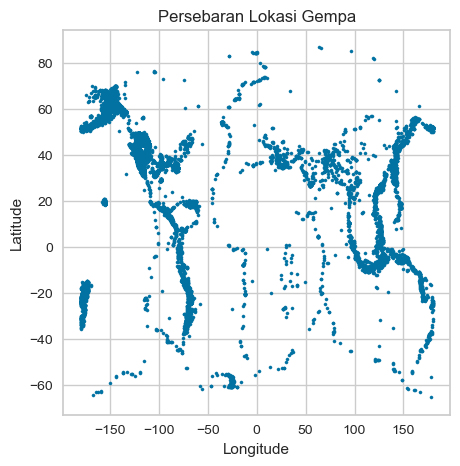

In [12]:
# Persebaran lokasi gempa
plt.figure(figsize=(5, 5))
plt.scatter(gempa_feature["longitude"], gempa_feature["latitude"], s=5)
plt.title("Persebaran Lokasi Gempa")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

5. Histogram 

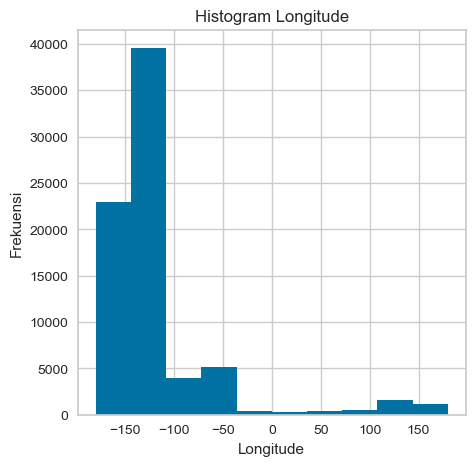

In [13]:
plt.figure(figsize=(5,5))
plt.hist(gempa_feature["longitude"])
plt.title("Histogram Longitude")
plt.xlabel("Longitude")
plt.ylabel("Frekuensi")
plt.show()

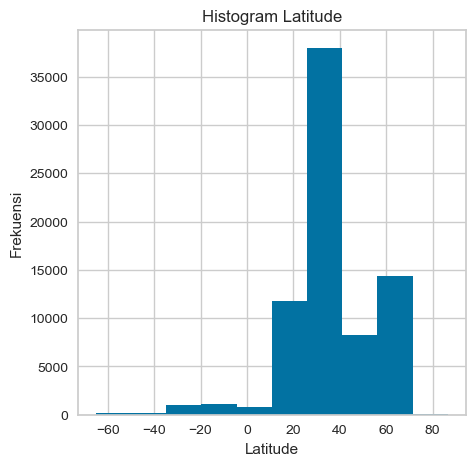

In [14]:
plt.figure(figsize=(5,5))
plt.hist(gempa_feature["latitude"])
plt.title("Histogram Latitude")
plt.xlabel("Latitude")
plt.ylabel("Frekuensi")
plt.show()

# Data Preparation

1.  Dataset Reduction (Sampling)

In [15]:
gempa_sample = gempa_feature.sample(n=1827, random_state=42)

kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_label = kmeans.fit_predict(gempa_sample)

gempa_sample.shape

C:\Users\user\anaconda3\envs\datnal\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


(1827, 2)

2. Normalisasi Data

In [16]:
gempa_sample.head()

,latitude,longitude
9330,62.840800,-151.779300
19031,36.026833,-117.384834
38866,36.542835,-121.129334
49361,61.015000,-152.364600
50074,38.821167,-122.782837


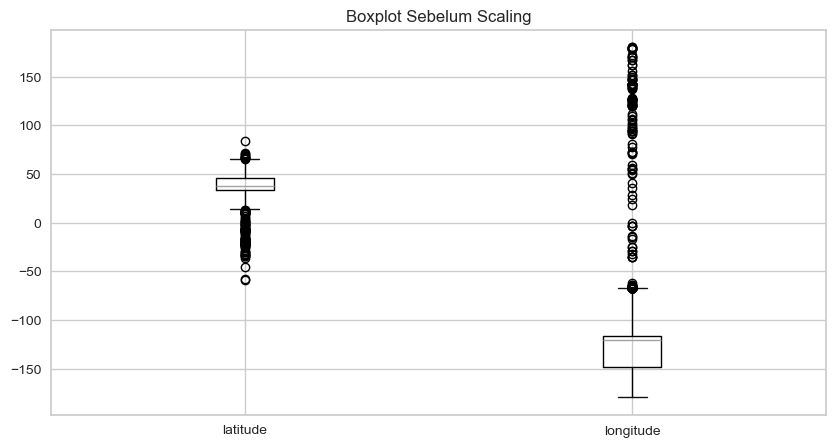

In [17]:
plt.figure(figsize=(10, 5))
gempa_sample.boxplot()
plt.title("Boxplot Sebelum Scaling")
plt.show()

In [18]:
scaler = StandardScaler()
gempa_sample = scaler.fit_transform(gempa_sample)

gempa_sample = pd.DataFrame(gempa_sample, columns=fitur_utama)

gempa_sample.head()

,latitude,longitude
0,1.438493,-0.660867
1,-0.079348,-0.087048
2,-0.050139,-0.149519
3,1.335141,-0.670632
4,0.078829,-0.177106


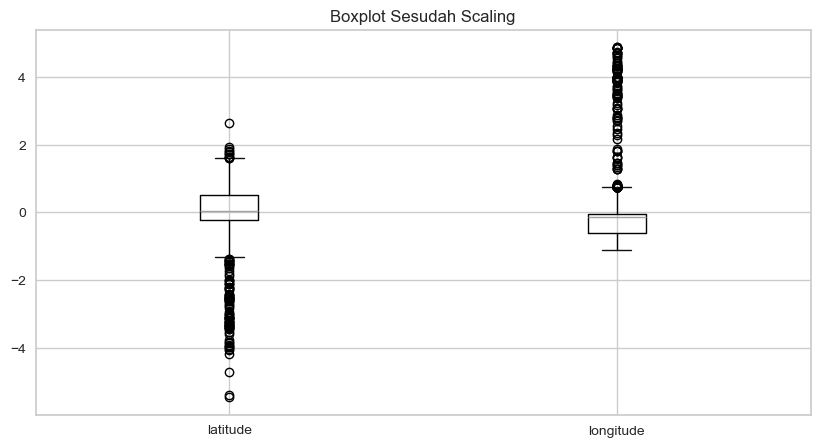

In [19]:
plt.figure(figsize=(10, 5))
gempa_sample.boxplot()
plt.title("Boxplot Sesudah Scaling")
plt.show()

# Modeling

## K-MEANS

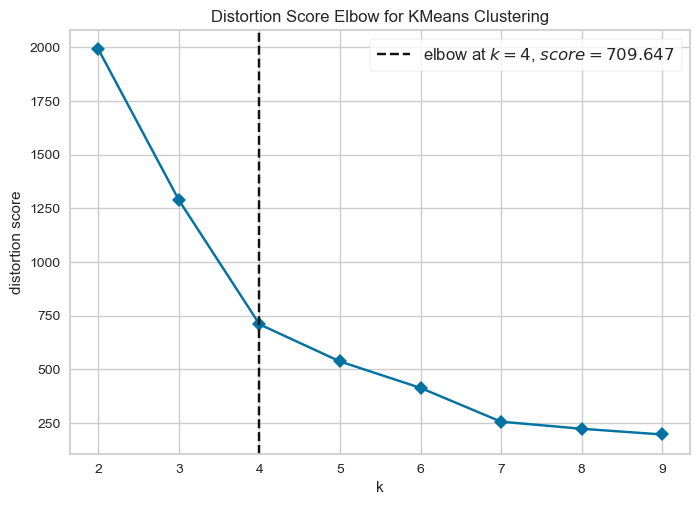

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [20]:
elbowModel = KMeans(random_state=42)

elbowVisu = KElbowVisualizer(
    elbowModel,
    k=(2, 10),
    metric='distortion',
    timings=False
)

elbowVisu.fit(gempa_sample)
elbowVisu.show()

In [21]:
kmeans = KMeans(n_clusters=4, random_state=42)
cluster_labels = kmeans.fit_predict(gempa_sample)

gempa_sample["cluster"] = cluster_labels

centroids = kmeans.cluster_centers_
centroids

array([[ 0.00866225, -0.07937331],
       [-1.23909083,  3.89329238],
       [-1.38773941, -0.02942908],
       [ 1.30273017, -0.66354244]])

In [22]:
cluster_counts = gempa_sample['cluster'].value_counts().sort_index()
cluster_counts

cluster
0    1043
1      91
2     297
3     396
Name: count, dtype: int64

In [23]:
cluster_averages = gempa_sample.groupby('cluster').mean()
cluster_averages

,latitude,longitude
cluster,,
0,0.008662,-0.079373
1,-1.239091,3.893292
2,-1.387739,-0.029429
3,1.302730,-0.663542


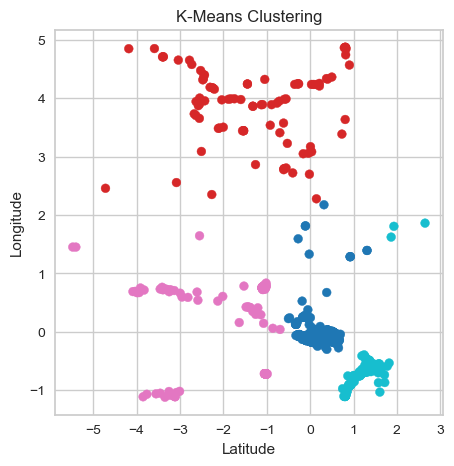

In [24]:
plt.figure(figsize=(5,5))

plt.scatter(
    gempa_sample['latitude'],
    gempa_sample['longitude'],
    c=gempa_sample['cluster'],
    cmap='tab10',
    s=40
)

plt.xlabel('Latitude')
plt.ylabel('Longitude')
plt.title('K-Means Clustering')
plt.show()


In [25]:
kmeans_labels = kmeans.fit_predict(gempa_sample)

sil_kmeans = silhouette_score(gempa_sample, kmeans_labels)
print(f"Silhouette Score K-Means: {sil_kmeans:.3f}")

Silhouette Score K-Means: 0.823


## DBSCAN

In [26]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(gempa_sample)

gempa_sample['dbscan_cluster'] = dbscan.labels_
gempa_sample['dbscan_cluster']

0       0
1       1
2       1
3       0
4       1
       ..
1822    1
1823    1
1824    1
1825    0
1826    1
Name: dbscan_cluster, Length: 1827, dtype: int64

In [27]:
gempa_sample['dbscan_cluster'].value_counts()

dbscan_cluster
 1    1032
 0     393
 3     138
 5     118
 2      83
 6      24
-1      21
 4      13
 7       5
Name: count, dtype: int64

In [28]:
dbscan_cluster_avg = gempa_sample.groupby('dbscan_cluster').mean()
dbscan_cluster_avg

,latitude,longitude,cluster
dbscan_cluster,,,
-1,-1.204313,2.143661,1.190476
0,1.296269,-0.682063,3.000000
1,0.003351,-0.095757,0.000000
2,-1.159955,3.965106,1.000000
3,-1.027408,-0.722163,2.000000
4,-3.318393,-1.078144,2.000000
5,-1.114537,0.706811,2.000000
6,-3.345040,0.682511,2.000000
7,1.078628,1.328250,0.000000


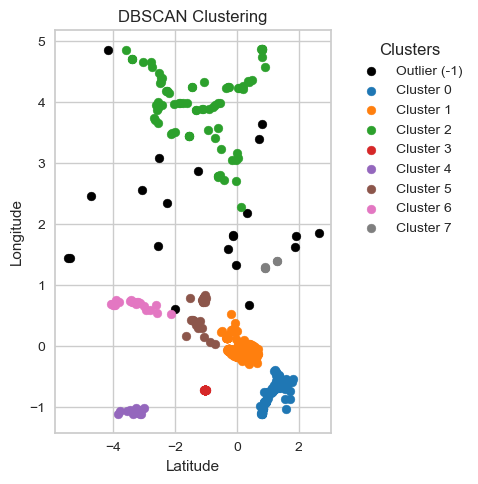

In [29]:
plt.figure(figsize=(5,5))

# pisahkan outlier dan cluster biasa
clusters = gempa_sample['dbscan_cluster'].unique()
clusters = np.sort(clusters)

for c in clusters:
    if c == -1:
        # outlier
        color = "black"
        label = "Outlier (-1)"
    else:
        color = plt.cm.tab10(c % 10)  # warna tab10
        label = f"Cluster {c}"
    
    subset = gempa_sample[gempa_sample['dbscan_cluster'] == c]
    plt.scatter(
        subset['latitude'],
        subset['longitude'],
        c=[color],
        s=40,
        label=label
    )

plt.xlabel("Latitude")
plt.ylabel("Longitude")
plt.title("DBSCAN Clustering")
plt.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [30]:
sil_dbscan = silhouette_score(gempa_sample, gempa_sample['dbscan_cluster'])
print(f"\nSilhouette Score DBSCAN: {sil_dbscan:.3f}")


Silhouette Score DBSCAN: 0.899


# Evaluation: Perbandingan Algoritma

In [31]:
results = {
    "Algoritma": ["K-Means", "DBSCAN"],
    "Silhouette Score": [sil_kmeans, sil_dbscan]
}

eval_gempa = pd.DataFrame(results)
eval_gempa

,Algoritma,Silhouette Score
0,K-Means,0.823289
1,DBSCAN,0.899497


# OPTIMALIZATION

In [32]:
eps_list = [0.5, 0.7, 0.9]
min_samples_list = [3, 5]

best_score = -1
best_params = None

for eps in eps_list:
    for m in min_samples_list:
        db = DBSCAN(eps=eps, min_samples=m).fit(gempa_sample)
        labels = db.labels_

        if len(set(labels)) > 1:
            score = silhouette_score(gempa_sample, dbscan_labels)
            print(f"eps={eps}, min_samples={m}, silhouette={score:.3f}")

            if score > best_score:
                best_score = score
                best_params = (eps, m)


print("\nPARAMETER TERBAIK:", best_params)
print("Silhouette terbaik :", round(best_score, 3))


eps=0.5, min_samples=3, silhouette=0.899
eps=0.5, min_samples=5, silhouette=0.899
eps=0.7, min_samples=3, silhouette=0.899
eps=0.7, min_samples=5, silhouette=0.899
eps=0.9, min_samples=3, silhouette=0.899
eps=0.9, min_samples=5, silhouette=0.899

PARAMETER TERBAIK: (0.5, 3)
Silhouette terbaik : 0.899


In [33]:
eps_best, min_best = best_params
db_best = DBSCAN(eps=eps_best, min_samples=min_best).fit(gempa_sample)
labels_best = db_best.labels_

gempa_sample['dbscan_cluster'] = labels_best

In [34]:
mask = labels_best != -1

sil_no_noise = silhouette_score(
    gempa_sample[mask],
    labels_best[mask]
)

print("\nSilhouette tanpa noise:", round(sil_no_noise, 3))
print("Jumlah noise (-1):", sum(labels_best == -1))
print("Jumlah cluster:", len(set(labels_best)) - (1 if -1 in labels_best else 0))


Silhouette tanpa noise: 0.91
Jumlah noise (-1): 17
Jumlah cluster: 9


In [35]:
X_stack = np.column_stack([
    kmeans_labels,
    dbscan_labels])

In [36]:
meta = DBSCAN(eps=eps_best, min_samples=min_best)
final_labels = meta.fit_predict(X_stack)

gempa_sample['kmeans_cluster'] = kmeans_labels
gempa_sample['dbscan_cluster'] = dbscan_labels
gempa_sample['final_cluster'] = final_labels

In [37]:
gempa_sample['final_cluster'].value_counts()

final_cluster
1     1032
0      393
3      138
6      118
2       83
7       24
5       13
4        8
11       6
10       5
8        4
9        3
Name: count, dtype: int64

In [38]:
final_cluster_avg = gempa_sample.groupby('final_cluster').mean()
final_cluster_avg.head()

,latitude,longitude,cluster,dbscan_cluster,kmeans_cluster
final_cluster,,,,,
0,1.296269,-0.682063,3.0,0.0,1.0
1,0.003351,-0.095757,0.0,1.0,0.0
2,-1.159955,3.965106,1.0,2.0,3.0
3,-1.027408,-0.722163,2.0,3.0,2.0
4,-2.060129,3.148231,1.0,-1.0,3.0


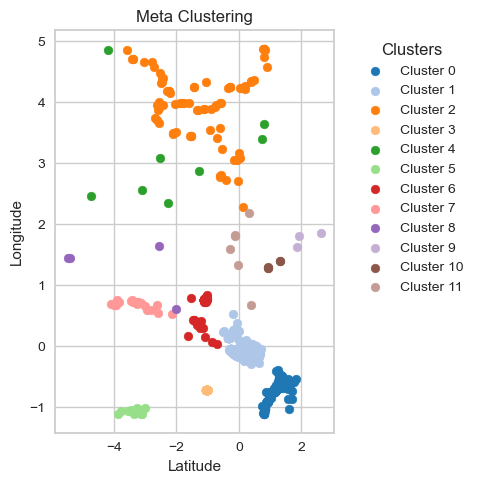

In [39]:
plt.figure(figsize=(5,5))

# pisahkan outlier dan cluster biasa
clusters = gempa_sample['final_cluster'].unique()
clusters = np.sort(clusters)

for c in clusters:
    if c == -1:
        # outlier
        color = "black"
        label = "Outlier (-1)"
    else:
        color = plt.cm.tab20(c % 20)  # warna tab10
        label = f"Cluster {c}"
    
    subset = gempa_sample[gempa_sample['final_cluster'] == c]
    plt.scatter(
        subset['latitude'],
        subset['longitude'],
        c=[color],
        s=40,
        label=label
    )

plt.xlabel("Latitude")
plt.ylabel("Longitude")
plt.title("Meta Clustering")
plt.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [40]:
sil_final = silhouette_score(gempa_sample, final_labels)
print("Silhouette Meta-Clustering:", sil_final)

Silhouette Meta-Clustering: 0.9172433125622714


# Evaluation: Perbandingan Algoritma

In [41]:
results_opt = {
    "Algoritma": ["K-Means", "DBSCAN", "DBSCAN w/o outlier", "Meta-Clustering"],
    "Silhouette Score": [sil_kmeans, sil_dbscan,sil_no_noise, sil_final]
}

eval_gempa_opt = pd.DataFrame(results_opt)
eval_gempa_opt

,Algoritma,Silhouette Score
0,K-Means,0.823289
1,DBSCAN,0.899497
2,DBSCAN w/o outlier,0.909743
3,Meta-Clustering,0.917243


## <div align="center"> Conclusion </div>

### Enter Your Conclusion Here:

1. K-Means
- Mengelompokkan data gempa berdasarkan latitude dan longitude
- Silhouette Score: 0.823289
- Bentuk cluster cenderung bulat, kurang cocok untuk pola gempa yang tidak beraturan

2. DBSCAN
- Lebih baik dalam mendeteksi area berkepadatan tinggi dan mengenali outlier
- Silhouette Score: 0.899497, lebih tinggi daripada K-Means

3. DBSCAN tanpa Outlier
- Menghapus titik berlabel -1 dari perhitungan evaluasi
- Silhouette Score meningkat sedikit menjadi 0.909743
- Outlier tidak memiliki pengaruh besar terhadap kualitas cluster

4. Meta-Clustering
- Menggabungkan hasil kedua algoritma, lalu diklasterisasi ulang memakai DBSCAN optimal
- Silhouette Score tertinggi: 0.917243
- Metode terbaik karena memanfaatkan kelebihan kedua algoritma

In [43]:
studentName2 = "Valerie Kurniawan"
studentNIM2 = "00000108382"
studentClass2 = "CL"

In [44]:
print("Name: \t\t{}".format(studentName2))
print("NIM: \t\t{}".format(studentNIM2))
print("Class: \t\t{}".format(studentClass2))
print("End: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Valerie Kurniawan
NIM: 		00000108382
Class: 		CL
End: 		2025-12-15 14:19:26.840940
Device ID: 	639aa66f-d986-11f0-833e-d843ae383bb6
